In [83]:
import json
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [84]:
root_path = "../"

trizod_filename = os.path.join(root_path, "datasets/cleaned_trizod_dataset.csv")
trizod_df = pd.read_csv(
    trizod_filename,
    index_col="label",
    converters={"gscores": lambda x: np.array(json.loads(x), dtype=float)},
)
df_train = trizod_df[~trizod_df["is_test"]]
df_test = trizod_df[trizod_df["is_test"]]

In [85]:
filename = "test1.csv"

if not os.path.exists(filename):
    fasta_filename = "test.fasta"
    with open(fasta_filename, "w") as f:
        for label, row in df_test.iterrows():
            f.write(f">{label}\n{row['sequence']}\n")

    subprocess.run(
        [
            "python",
            os.path.join(root_path, "predict.py"),
            "--fasta",
            fasta_filename,
            "--out",
            filename,
            "--save-member-gscores",
            # "--ensemble-id",
            # "seed883_n5",
        ],
        check=True,
    )
    os.remove(fasta_filename)
df_inferred = pd.read_csv(
    filename,
    index_col="label",
    converters={
        "gscores": lambda x: np.array(json.loads(x), dtype=float),
        "gscores_std": lambda x: np.array(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.array(json.loads(x), dtype=float),
    },
)
df_inferred

Loading ensemble from /home/michele/workdir/ADOPT2g/data/ensembles/seed42_n5/manifest.json...
  Ensemble ID: seed42_n5
  Ensemble size: 5
  Calibration factor: 4.1434
  Loading ESM model to cuda...


Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t33_650M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/home/michele/miniforge3/envs/adopt2g/lib/python3.12/site-packages/torch/cuda/__init__.py:283: UserWarning: 
    Found GPU0 NVIDIA GB10 which is of cuda capability 12.1.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (8.0) - (12.0)
    
  warnings.warn(


  Loading 5 ST models...
  Loading 5 MLP heads...
Running in ensemble mode (predictions include uncertainty)
  Saving per-member gscores
Processing 1 chunks, max 8_358 residues per batch


100%|██████████| 1/1 [00:07<00:00,  7.55s/it]               


Combining chunks...
Results saved to test1.csv
Columns: label, sequence, mean_gscore, mean_gscore_std, gscores, gscores_std, member_gscores
  - mean_gscore_std: calibrated std across ensemble members of per-member mean_gscore
  - gscores_std: calibrated per-residue std across ensemble members (JSON array)
  - member_gscores: per-residue gscores for each ensemble member (JSON 2D array)
(Use json.loads() to parse JSON array columns)


,sequence,mean_gscore,mean_gscore_std,gscores,gscores_std,member_gscores
label,,,,,,
623_1_1_1,FKLGGRDSRSGSPMARR,0.518536,0.237433,"[0.3065425455570221, 0.424462229013443, 0.3714...","[0.24760323762893677, 0.38868600130081177, 0.3...","[[0.3430176079273224, 0.4374016225337982, 0.37..."
1515_1_1_1,RERIDLLWKIARAGARSAVG,0.296878,0.369441,"[0.25466781854629517, 0.20870380103588104, 0.1...","[0.13033533096313477, 0.12505869567394257, 0.1...","[[0.21773512661457062, 0.20262855291366577, 0...."
1698_1_1_1,XLYENKPRRPYIL,0.341792,0.253052,"[nan, 0.34462833404541016, 0.35735949873924255...","[nan, 0.16196760535240173, 0.17595906555652618...","[[nan, 0.41496890783309937, 0.4250113964080810..."
1997_1_1_1,RYVVLPRPVCFEKGMNYTVR,0.369739,0.544937,"[0.24447481334209442, 0.4135836958885193, 0.37...","[0.23058094084262848, 0.7420060634613037, 0.66...","[[0.18106171488761902, 0.21849967539310455, 0...."
3322_1_1_1,GSCWAQSQGYNCCNNPSSTKVEYTDASGQWGVQNGQWCGIDYSYGQ...,0.154626,0.083420,"[0.20361606776714325, 0.14023511111736298, 0.1...","[0.15538465976715088, 0.13181358575820923, 0.0...","[[0.26480135321617126, 0.16368764638900757, 0...."
...,...,...,...,...,...,...
52503_1_1_1,MKVAVVRTPPKSPSSAKSRLQTAPVPMPDLKNVKSKIGSTENLKHQ...,0.833674,0.053962,"[0.7342711687088013, 0.7792491912841797, 0.807...","[0.18694910407066345, 0.20398923754692078, 0.1...","[[0.6796057224273682, 0.7052252888679504, 0.73..."
52589_1_1_1,GAMGKSLSHLPLHSSKEDAYDGVTSENMRNGLVNSEVHNEDGRNGD...,0.814760,0.082787,"[0.7231078147888184, 0.7381721138954163, 0.806...","[0.35373979806900024, 0.3058110773563385, 0.11...","[[0.7792466282844543, 0.7834396362304688, 0.77..."
52737_1_1_1,MPGHLQEGFGCVVTNRFDQLFDDESDPFEVLKAAENKKKEAGGGGV...,0.848095,0.099632,"[0.6877689957618713, 0.729709804058075, 0.8120...","[0.3917694687843323, 0.21850450336933136, 0.31...","[[0.7225183248519897, 0.7313326597213745, 0.82..."


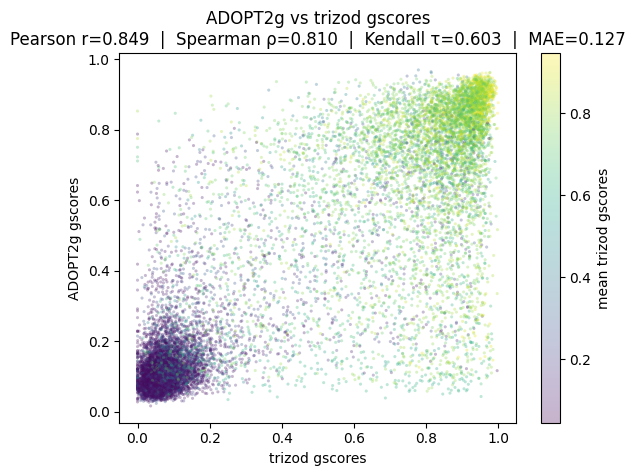

Summary of metrics for each member and mean prediction:

member_id  pearson_r  spearman_rho  kendall_tau    mae
     mean     0.8492        0.8101       0.6026 0.1266
        0     0.8314        0.7942       0.5876 0.1316
        1     0.8267        0.7910       0.5819 0.1344
        2     0.8442        0.8035       0.5948 0.1278
        3     0.8419        0.7975       0.5875 0.1291
        4     0.8347        0.7950       0.5866 0.1313
No members have better metrics than the mean prediction.


In [86]:
from scipy.stats import kendalltau, pearsonr, spearmanr

member_metrics = []
mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
trizod_gscores = np.concatenate(df_test["gscores"].values)
adopt2_gscores = np.concatenate(df_inferred["gscores"].values)
mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

# Compute correlation metrics
pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

# Also compute MAE for prediction accuracy
mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

member_metrics.append(
    {
        "member_id": "mean",
        "pearson_r": pearson_r,
        "spearman_rho": spearman_rho,
        "kendall_tau": kendall_tau,
        "mae": mae,
    }
)

plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
plt.xlabel("trizod gscores")
plt.ylabel("ADOPT2g gscores")
plt.title(
    f"ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
)
plt.colorbar(label="mean trizod gscores")
plt.show()

n_members = len(df_inferred["member_gscores"].iloc[0]) if "member_gscores" in df_inferred.columns else 0

# Prepare to collect summary stats for each member
for m in range(n_members):
    mean_trizod_gscores = np.repeat(df_test["gscores"].apply(np.nanmean).values, df_test["gscores"].apply(len).values)
    trizod_gscores = np.concatenate(df_test["gscores"].values)
    # Select the gscores for the current member 'm' from the 2D list in each row, then flatten
    adopt2_gscores = np.concatenate([gscores[m] for gscores in df_inferred["member_gscores"].values])
    mask = np.isfinite(trizod_gscores) & np.isfinite(adopt2_gscores)

    # Compute correlation metrics
    pearson_r, _ = pearsonr(trizod_gscores[mask], adopt2_gscores[mask])
    spearman_rho, _ = spearmanr(trizod_gscores[mask], adopt2_gscores[mask])
    kendall_tau, _ = kendalltau(trizod_gscores[mask], adopt2_gscores[mask])

    # Also compute MAE for prediction accuracy
    mae = np.mean(np.abs(trizod_gscores[mask] - adopt2_gscores[mask]))

    member_metrics.append(
        {
            "member_id": m,
            "pearson_r": pearson_r,
            "spearman_rho": spearman_rho,
            "kendall_tau": kendall_tau,
            "mae": mae,
        }
    )

    # plt.scatter(trizod_gscores, adopt2_gscores, alpha=0.3, s=5, lw=0, c=mean_trizod_gscores)
    # plt.xlabel("trizod gscores")
    # plt.ylabel("ADOPT2g gscores")
    # plt.title(
    #     f"m={m}: ADOPT2g vs trizod gscores\nPearson r={pearson_r:.3f}  |  Spearman ρ={spearman_rho:.3f}  |  Kendall τ={kendall_tau:.3f}  |  MAE={mae:.3f}",
    # )
    # plt.colorbar(label="mean trizod gscores")
    # plt.show()

if n_members > 0:
    summary_df = pd.DataFrame(member_metrics)
    print("Summary of metrics for each member and mean prediction:\n")
    print(summary_df.to_string(index=False, float_format="%.4f"))

    # Check if any member has better metric than mean
    # Lower MAE is better, higher correlation is better
    mae_mean = summary_df["mae"][summary_df["member_id"] == "mean"].values[0]
    pearson_r_mean = summary_df["pearson_r"][summary_df["member_id"] == "mean"].values[0]
    spearman_rho_mean = summary_df["spearman_rho"][summary_df["member_id"] == "mean"].values[0]
    kendall_tau_mean = summary_df["kendall_tau"][summary_df["member_id"] == "mean"].values[0]

    better_mae_members = summary_df[summary_df["mae"] < mae_mean]["member_id"].tolist()
    better_pearson_members = summary_df[summary_df["pearson_r"] > pearson_r_mean]["member_id"].tolist()
    better_spearman_members = summary_df[summary_df["spearman_rho"] > spearman_rho_mean]["member_id"].tolist()
    better_kendall_members = summary_df[summary_df["kendall_tau"] > kendall_tau_mean]["member_id"].tolist()

    if better_mae_members or better_pearson_members or better_spearman_members or better_kendall_members:
        print("\nWARNING: Some members have better metrics than the mean prediction:")
        if better_mae_members:
            print(f"  Members with lower MAE than mean: {better_mae_members}")
        if better_pearson_members:
            print(f"  Members with higher Pearson r than mean: {better_pearson_members}")
        if better_spearman_members:
            print(f"  Members with higher Spearman rho than mean: {better_spearman_members}")
        if better_kendall_members:
            print(f"  Members with higher Kendall tau than mean: {better_kendall_members}")
    else:
        print("No members have better metrics than the mean prediction.")


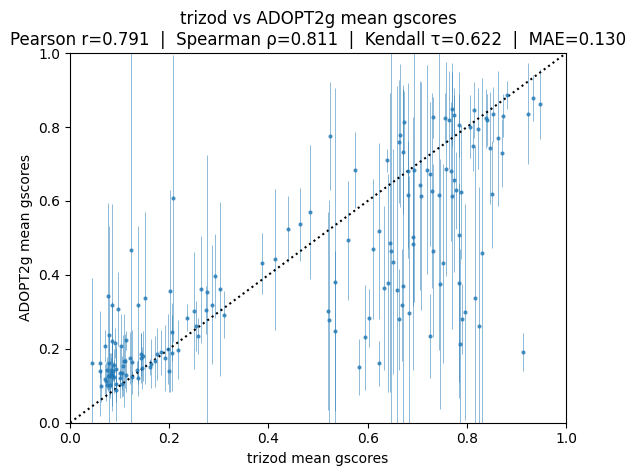

In [87]:
# Compute correlation metrics for mean gscores
pearson_r_mean, _ = pearsonr(df_test["mean_gscore"], df_inferred["mean_gscore"])
spearman_rho_mean, _ = spearmanr(df_test["mean_gscore"], df_inferred["mean_gscore"])
kendall_tau_mean, _ = kendalltau(df_test["mean_gscore"], df_inferred["mean_gscore"])
mae_mean = np.mean(np.abs(df_test["mean_gscore"].values - df_inferred["mean_gscore"].values))

plt.errorbar(
    df_test["mean_gscore"],
    df_inferred["mean_gscore"],
    yerr=df_inferred["mean_gscore_std"],
    fmt="o",
    markersize=2,
    elinewidth=0.5,
    alpha=0.7,
    capsize=0,
)
plt.xlabel("trizod mean gscores")
plt.ylabel("ADOPT2g mean gscores")
plt.title(
    f"trizod vs ADOPT2g mean gscores\nPearson r={pearson_r_mean:.3f}  |  Spearman ρ={spearman_rho_mean:.3f}  |  Kendall τ={kendall_tau_mean:.3f}  |  MAE={mae_mean:.3f}",
)
plt.axline((0.5, 0.5), slope=1, color="k", ls=":")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()


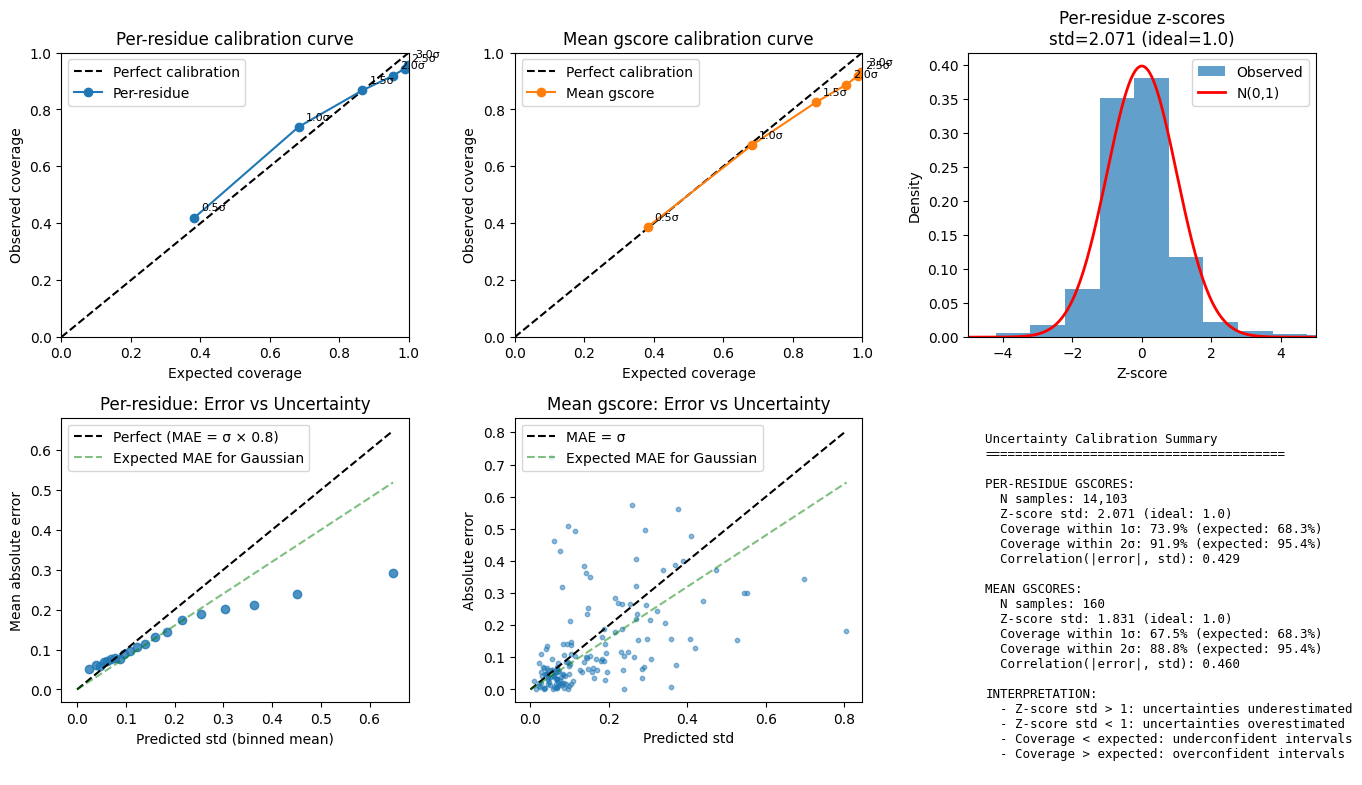

In [88]:
# Uncertainty calibration analysis
# For well-calibrated uncertainties, ~68% of true values should fall within ±1σ, ~95% within ±2σ

# --- Per-residue uncertainty calibration ---
trizod_gscores = np.concatenate(df_test["gscores"].values)
pred_gscores = np.concatenate(df_inferred["gscores"].values)
pred_gscores_std = np.concatenate(df_inferred["gscores_std"].values)

# Mask for valid values
mask = np.isfinite(trizod_gscores) & np.isfinite(pred_gscores) & np.isfinite(pred_gscores_std) & (pred_gscores_std > 0)
true_vals = trizod_gscores[mask]
pred_vals = pred_gscores[mask]
pred_stds = pred_gscores_std[mask]

# Compute z-scores (normalized residuals)
residuals = true_vals - pred_vals
z_scores = residuals / pred_stds

# Calibration: fraction of points within n standard deviations
n_sigmas = np.array([0.5, 1, 1.5, 2, 2.5, 3])
expected_coverage = 2 * (
    0.5 - (1 - np.vectorize(lambda x: __import__("scipy.stats", fromlist=["norm"]).norm.cdf(x))(n_sigmas))
)
# Simpler: expected for Gaussian
from scipy.stats import norm

expected_coverage = np.array([norm.cdf(n) - norm.cdf(-n) for n in n_sigmas])
observed_coverage_residue = np.array([np.mean(np.abs(z_scores) <= n) for n in n_sigmas])

# --- Mean gscore uncertainty calibration ---
true_mean = df_test["mean_gscore"].values
pred_mean = df_inferred["mean_gscore"].values
pred_mean_std = df_inferred["mean_gscore_std"].values

mask_mean = np.isfinite(true_mean) & np.isfinite(pred_mean) & np.isfinite(pred_mean_std) & (pred_mean_std > 0)
residuals_mean = true_mean[mask_mean] - pred_mean[mask_mean]
z_scores_mean = residuals_mean / pred_mean_std[mask_mean]

observed_coverage_mean = np.array([np.mean(np.abs(z_scores_mean) <= n) for n in n_sigmas])

# --- Plotting ---
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 1. Calibration curve - Per-residue
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_residue, "o-", color="tab:blue", label="Per-residue")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Per-residue calibration curve")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_residue[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 2. Calibration curve - Mean gscore
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
ax.plot(expected_coverage, observed_coverage_mean, "o-", color="tab:orange", label="Mean gscore")
ax.set_xlabel("Expected coverage")
ax.set_ylabel("Observed coverage")
ax.set_title("Mean gscore calibration curve")
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
for i, n in enumerate(n_sigmas):
    ax.annotate(
        f"{n}σ",
        (expected_coverage[i], observed_coverage_mean[i]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8,
    )

# 3. Z-score histogram - Per-residue
ax = axes[0, 2]
ax.hist(z_scores, bins=100, density=True, alpha=0.7, label="Observed")
x_range = np.linspace(-5, 5, 200)
ax.plot(x_range, norm.pdf(x_range), "r-", lw=2, label="N(0,1)")
ax.set_xlabel("Z-score")
ax.set_ylabel("Density")
ax.set_title(f"Per-residue z-scores\nstd={np.std(z_scores):.3f} (ideal=1.0)")
ax.legend()
ax.set_xlim(-5, 5)

# 4. Error vs predicted std - Per-residue (binned)
ax = axes[1, 0]
abs_errors = np.abs(residuals)
# Bin by predicted std
n_bins = 20
std_bins = np.percentile(pred_stds, np.linspace(0, 100, n_bins + 1))
bin_centers = []
mean_errors = []
mean_stds = []
for i in range(n_bins):
    in_bin = (pred_stds >= std_bins[i]) & (pred_stds < std_bins[i + 1])
    if np.sum(in_bin) > 10:
        bin_centers.append(np.mean(pred_stds[in_bin]))
        mean_errors.append(np.mean(abs_errors[in_bin]))
        mean_stds.append(np.mean(pred_stds[in_bin]))
ax.scatter(bin_centers, mean_errors, alpha=0.8)
max_val = max(max(bin_centers), max(mean_errors))
ax.plot([0, max_val], [0, max_val], "k--", label="Perfect (MAE = σ × 0.8)")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Predicted std (binned mean)")
ax.set_ylabel("Mean absolute error")
ax.set_title("Per-residue: Error vs Uncertainty")
ax.legend()

# 5. Error vs predicted std - Mean gscore
ax = axes[1, 1]
abs_errors_mean = np.abs(residuals_mean)
ax.scatter(pred_mean_std[mask_mean], abs_errors_mean, alpha=0.5, s=10)
max_val = max(pred_mean_std[mask_mean].max(), abs_errors_mean.max())
ax.plot([0, max_val], [0, max_val], "k--", label="MAE = σ")
ax.plot([0, max_val], [0, max_val * 0.8], "g--", alpha=0.5, label="Expected MAE for Gaussian")
ax.set_xlabel("Predicted std")
ax.set_ylabel("Absolute error")
ax.set_title("Mean gscore: Error vs Uncertainty")
ax.legend()

# 6. Summary statistics table
ax = axes[1, 2]
ax.axis("off")
summary_text = f"""Uncertainty Calibration Summary
{"=" * 40}

PER-RESIDUE GSCORES:
  N samples: {len(z_scores):,}
  Z-score std: {np.std(z_scores):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_residue[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_residue[3] * 100:.1f}% (expected: 95.4%)
  Correlation(|error|, std): {np.corrcoef(abs_errors, pred_stds)[0, 1]:.3f}

MEAN GSCORES:
  N samples: {len(z_scores_mean):,}
  Z-score std: {np.std(z_scores_mean):.3f} (ideal: 1.0)
  Coverage within 1σ: {observed_coverage_mean[1] * 100:.1f}% (expected: 68.3%)
  Coverage within 2σ: {observed_coverage_mean[3] * 100:.1f}% (expected: 95.4%)
  Correlation(|error|, std): {np.corrcoef(abs_errors_mean, pred_mean_std[mask_mean])[0, 1]:.3f}

INTERPRETATION:
  - Z-score std > 1: uncertainties underestimated
  - Z-score std < 1: uncertainties overestimated
  - Coverage < expected: underconfident intervals
  - Coverage > expected: overconfident intervals
"""
ax.text(0.05, 0.95, summary_text, transform=ax.transAxes, fontsize=9, verticalalignment="top", fontfamily="monospace")

plt.tight_layout()
plt.show()
